In [20]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('bike_sharing.csv')
df.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [21]:
df.shape

(10886, 12)

In [22]:
df.dtypes

datetime          str
season          int64
holiday         int64
workingday      int64
weather         int64
temp          float64
atemp         float64
humidity        int64
windspeed     float64
casual          int64
registered      int64
count           int64
dtype: object

In [23]:
df.isna().sum()

datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64

In [24]:
df.duplicated().sum()

np.int64(0)

In [25]:
df['weather'].value_counts()

weather
1    7192
2    2834
3     859
4       1
Name: count, dtype: int64

----

Convert datetime column from str to datetime and extract hour

In [26]:
df['datetime'] = pd.to_datetime(df['datetime'])
df['hour'] = df['datetime'].dt.hour

df.head(24)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,hour
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0000,3,13,16,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0000,8,32,40,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0000,5,27,32,2
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0000,3,10,13,3
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0000,0,1,1,4
5,2011-01-01 05:00:00,1,0,0,2,9.84,12.880,75,6.0032,0,1,1,5
6,2011-01-01 06:00:00,1,0,0,1,9.02,13.635,80,0.0000,2,0,2,6
7,2011-01-01 07:00:00,1,0,0,1,8.20,12.880,86,0.0000,1,2,3,7
8,2011-01-01 08:00:00,1,0,0,1,9.84,14.395,75,0.0000,1,7,8,8
9,2011-01-01 09:00:00,1,0,0,1,13.12,17.425,76,0.0000,8,6,14,9


In [27]:
df.groupby('hour')['count'].mean().sort_values(ascending=False)

hour
17    468.765351
18    430.859649
8     362.769231
16    316.372807
19    315.278509
13    257.787281
12    256.508772
15    254.298246
14    243.442982
20    228.517544
9     221.780220
7     213.116484
11    210.674725
10    175.092308
21    173.370614
22    133.576754
23     89.508772
6      76.259341
0      55.138462
1      33.859031
2      22.899554
5      19.767699
3      11.757506
4       6.407240
Name: count, dtype: float64

In [28]:
df.groupby('workingday')['count'].mean().sort_values(ascending=False)

workingday
1    193.011873
0    188.506621
Name: count, dtype: float64

Average of 193 bikes used on working days and 188 bikes used on non-working days. Slight 5 count difference but there could be different peaks at different times. Working days could have higher peaks around 7-8 AM and 5-6 PM, whereas Non-Working days could have higher peaks in the midday range.

<Axes: title={'center': 'Average Bike Rentals by Hour and Working Day Status'}, xlabel='hour'>

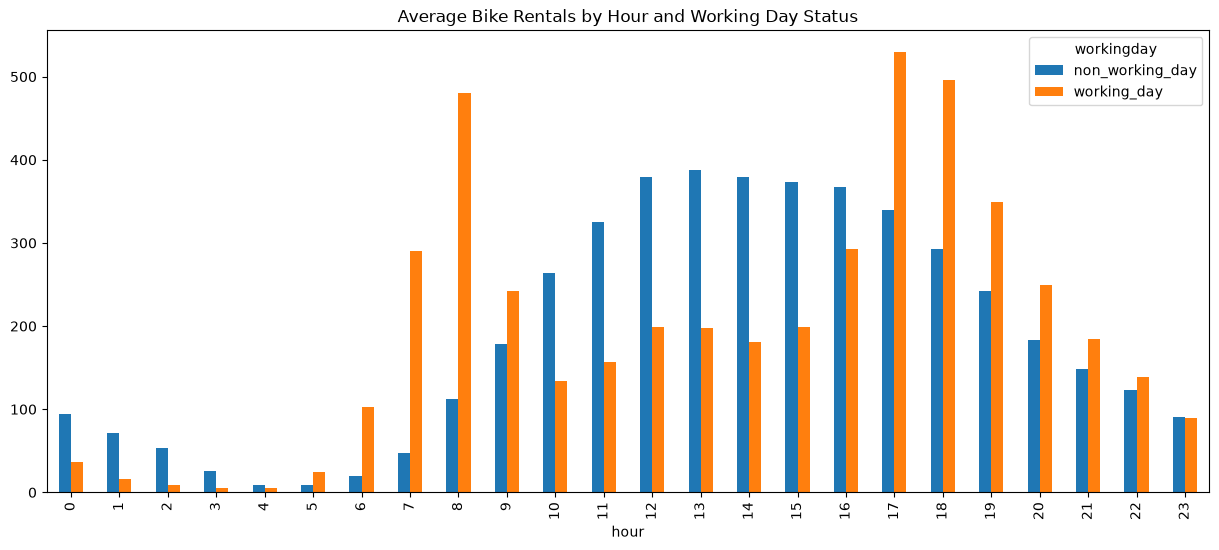

In [40]:
working_hrs_compare = df.groupby(['workingday', 'hour'])['count'].mean().unstack('workingday').rename(columns={0: 'non_working_day', 1: 'working_day'})
working_hrs_compare.plot(kind='bar', figsize=(15, 6), title='Average Bike Rentals by Hour and Working Day Status')

We can observe that during working days, bike traffic is the highest during rush hours whereas during non-working days, bike traffic is highest during mid-day for leisure and recreational bike rentals.

<Axes: title={'center': 'Average Bike Rentals by Hour and Weather Status'}, xlabel='hour'>

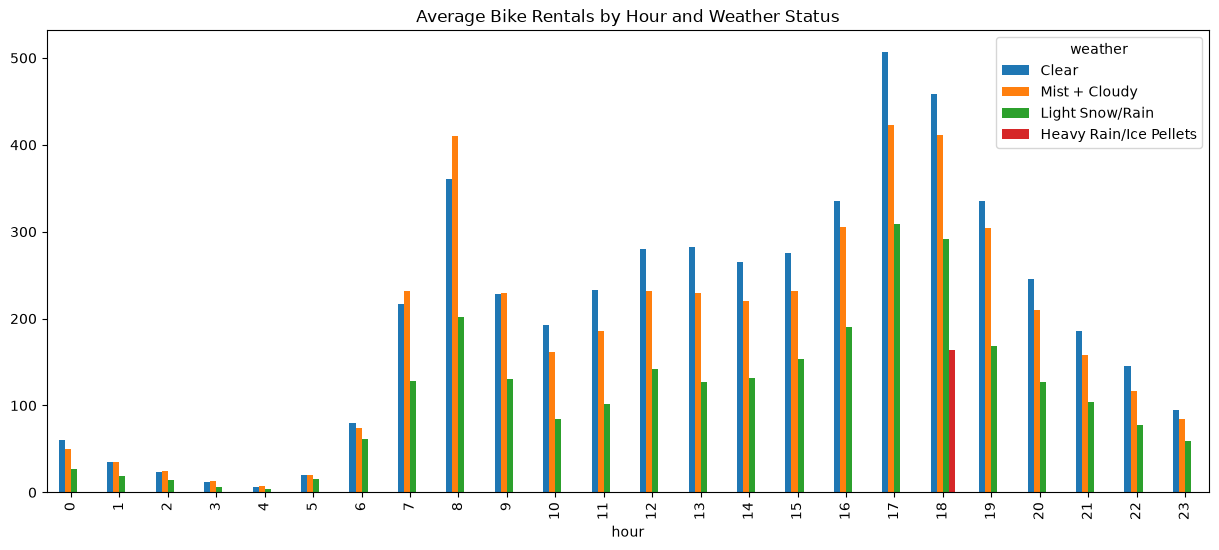

In [43]:
weather_compare = df.groupby(['weather', 'hour'])['count'].mean().unstack('weather').rename(columns={1: 'Clear', 2: 'Mist + Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Ice Pellets'})
weather_compare.plot(kind='bar', figsize=(15, 6), title='Average Bike Rentals by Hour and Weather Status')